In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

clean = pd.read_parquet("../data/processed/clean_transactions.parquet")
print(clean.shape)
clean.head()

(776827, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [11]:
returns = pd.read_parquet("../data/processed/returns.parquet")
returns = returns.dropna(subset=["CustomerID"]).copy()
returns["CustomerID"] = returns["CustomerID"].astype(int)
returns["Quantity"] = -returns["Quantity"]

big = clean[clean["Revenue"] > 30000]
check = big.merge(returns[["CustomerID", "StockCode", "Quantity", "InvoiceDate"]],
                  on=["CustomerID", "StockCode", "Quantity"], suffixes=("", "_return"))
check = check[check["InvoiceDate_return"] >= check["InvoiceDate"]]
print(len(big), "крупных строк;", len(check), "из них имеют отмену")
print(check[["Invoice", "CustomerID", "Quantity", "Revenue", "InvoiceDate", "InvoiceDate_return"]])

3 крупных строк; 3 из них имеют отмену
  Invoice  CustomerID  Quantity   Revenue         InvoiceDate  \
0  541431       12346     74215   77183.6 2011-01-18 10:01:00   
1  556444       15098        60   38970.0 2011-06-10 15:28:00   
2  581483       16446     80995  168469.6 2011-12-09 09:15:00   

   InvoiceDate_return  
0 2011-01-18 10:17:00  
1 2011-06-10 15:39:00  
2 2011-12-09 09:27:00  


In [12]:
to_drop = clean.index.isin(big.index)
print("удаляю строк:", to_drop.sum(), "| выручка до:", round(clean["Revenue"].sum()))
clean = clean[~to_drop].copy()
print("выручка после:", round(clean["Revenue"].sum()))

удаляю строк: 3 | выручка до: 17081129
выручка после: 16796506


In [13]:
print(clean[["Quantity", "Price", "Revenue"]].describe(percentiles=[.5, .9, .99, .999]))
print(clean.nlargest(10, "Revenue")[["Invoice", "StockCode", "Description", "Quantity", "Price", "Revenue", "CustomerID"]])

            Quantity          Price        Revenue
count  776824.000000  776824.000000  776824.000000
mean       13.315393       2.948923      21.622022
std        76.208416       4.317084      69.899698
min         1.000000       0.030000       0.060000
50%         6.000000       1.950000      12.480000
90%        24.000000       6.750000      35.400000
99%       144.000000      12.750000     201.600000
99.9%     576.000000      39.950000     830.000000
max     19152.000000     649.500000   15818.400000
       Invoice StockCode                          Description  Quantity  \
332104  530715     84347  ROTATING SILVER ANGELS T-LIGHT HLDR      9360   
169304  511465    15044A                  PINK PAPER PARASOL       3500   
630683  567423     23243  SET OF TEA COFFEE SUGAR TINS PANTRY      1412   
417625  540815     21108   FAIRY CAKE FLANNEL ASSORTED COLOUR      3114   
493340  550461     21108   FAIRY CAKE FLANNEL ASSORTED COLOUR      3114   
289835  525968     84347  ROTATING SILVE

In [14]:
orders = (
    clean.groupby(["Invoice", "CustomerID"], as_index=False)
    .agg(InvoiceDate=("InvoiceDate", "min"),
         Revenue=("Revenue", "sum"),
         Items=("Quantity", "sum"),
         Lines=("StockCode", "nunique"),
         Country=("Country", "first"))
)
print(orders.shape)
orders.head()

(36597, 7)


,Invoice,CustomerID,InvoiceDate,Revenue,Items,Lines,Country
0,489434,13085,2009-12-01 07:45:00,505.30,166,8,United Kingdom
1,489435,13085,2009-12-01 07:46:00,145.80,60,4,United Kingdom
2,489436,13078,2009-12-01 09:06:00,630.33,193,19,United Kingdom
3,489437,15362,2009-12-01 09:08:00,310.75,145,23,United Kingdom
4,489438,18102,2009-12-01 09:24:00,2286.24,826,17,United Kingdom


In [15]:
print(clean.groupby("Invoice")["CustomerID"].nunique().max())

1


In [16]:
orders.to_parquet("../data/processed/orders.parquet", index=False)

In [17]:
orders["OrderMonth"] = orders["InvoiceDate"].dt.to_period("M")
orders["CohortMonth"] = orders.groupby("CustomerID")["InvoiceDate"].transform("min").dt.to_period("M")

orders["CohortIndex"] = (
    (orders["OrderMonth"].dt.year - orders["CohortMonth"].dt.year) * 12
    + (orders["OrderMonth"].dt.month - orders["CohortMonth"].dt.month)
)
orders[["CustomerID", "InvoiceDate", "CohortMonth", "OrderMonth", "CohortIndex"]].head()

,CustomerID,InvoiceDate,CohortMonth,OrderMonth,CohortIndex
0,13085,2009-12-01 07:45:00,2009-12,2009-12,0
1,13085,2009-12-01 07:46:00,2009-12,2009-12,0
2,13078,2009-12-01 09:06:00,2009-12,2009-12,0
3,15362,2009-12-01 09:08:00,2009-12,2009-12,0
4,18102,2009-12-01 09:24:00,2009-12,2009-12,0


In [18]:
cohort_counts = (
    orders.groupby(["CohortMonth", "CohortIndex"])["CustomerID"]
    .nunique()
    .unstack(1)
)
cohort_size = cohort_counts[0]
retention = cohort_counts.div(cohort_size, axis=0)

retention.index = retention.index.astype(str)
print(cohort_size.head())
retention.iloc[:, :13].round(3)

CohortMonth
2009-12    951.0
2010-01    368.0
2010-02    375.0
2010-03    441.0
2010-04    294.0
Freq: M, Name: 0, dtype: float64


CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2009-12,1.0,0.350,0.333,0.425,0.379,0.360,0.376,0.344,0.338,0.362,0.422,0.496,0.376
2010-01,1.0,0.215,0.321,0.315,0.272,0.310,0.269,0.234,0.285,0.326,0.310,0.179,0.228
2010-02,1.0,0.235,0.227,0.293,0.245,0.197,0.192,0.288,0.256,0.277,0.115,0.125,0.152
2010-03,1.0,0.190,0.231,0.243,0.231,0.204,0.247,0.306,0.277,0.109,0.113,0.145,0.200
2010-04,1.0,0.190,0.190,0.160,0.184,0.221,0.276,0.265,0.105,0.109,0.075,0.139,0.143
2010-05,1.0,0.157,0.169,0.176,0.176,0.255,0.212,0.125,0.059,0.082,0.114,0.133,0.153
2010-06,1.0,0.176,0.187,0.206,0.232,0.285,0.127,0.090,0.082,0.112,0.105,0.139,0.150
2010-07,1.0,0.156,0.183,0.296,0.290,0.140,0.113,0.145,0.145,0.113,0.134,0.145,0.129
2010-08,1.0,0.196,0.288,0.325,0.166,0.117,0.098,0.129,0.135,0.129,0.129,0.117,0.147


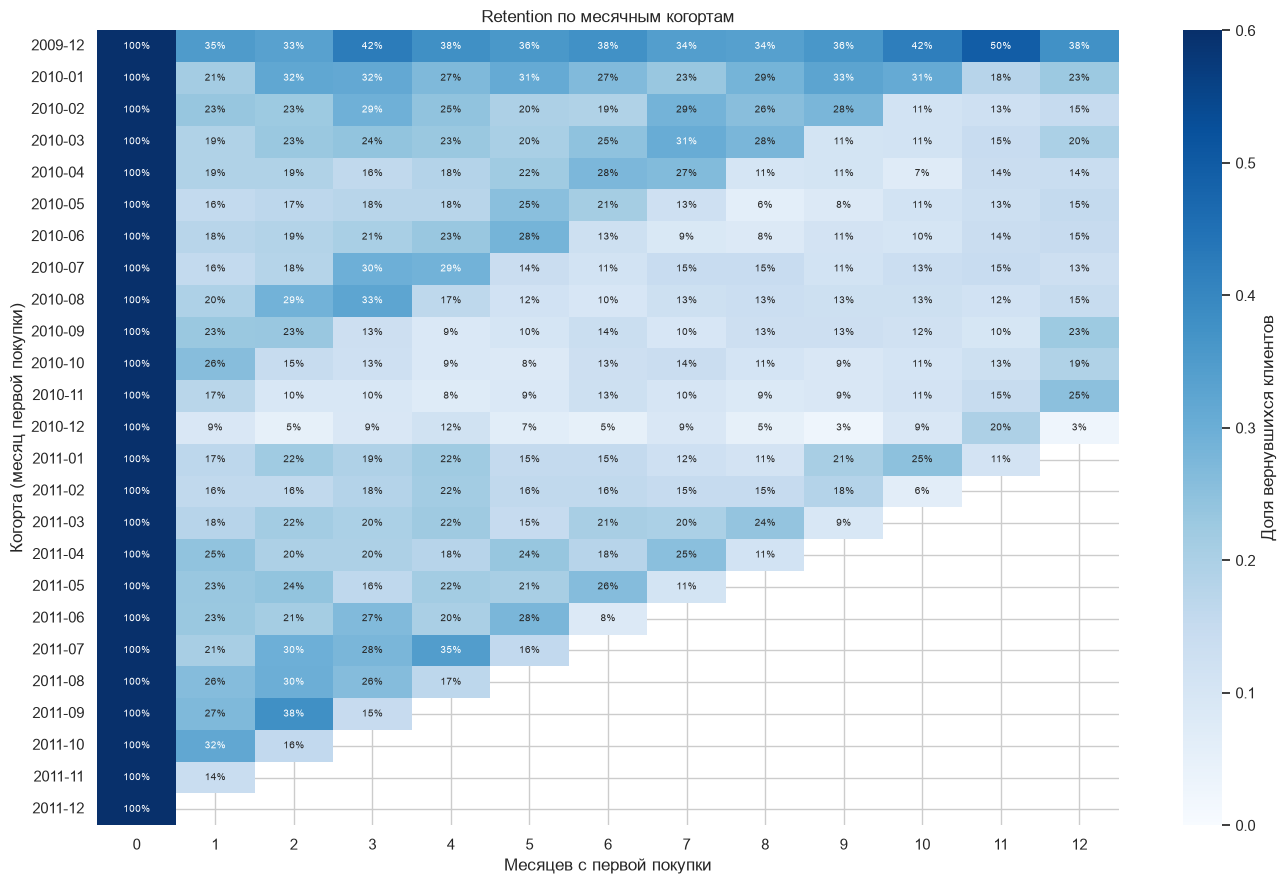

In [20]:
plt.figure(figsize=(14, 9))
sns.heatmap(retention.iloc[:, :13], annot=True, fmt=".0%", cmap="Blues",
            vmin=0, vmax=0.6, cbar_kws={"label": "Доля вернувшихся клиентов"},
            annot_kws={"size": 7})
plt.title("Retention по месячным когортам")
plt.xlabel("Месяцев с первой покупки")
plt.ylabel("Когорта (месяц первой покупки)")
plt.tight_layout()
plt.savefig("../reports/figures/cohort_retention.png", dpi=150)
plt.show()

In [21]:
avg_ret = retention.iloc[:, 1:13].mean().round(3)
print(avg_ret)
print("Размер когорты декабря 2009:", int(cohort_size.iloc[0]), "| средний размер остальных:", int(cohort_size.iloc[1:].mean()))

CohortIndex
1     0.210
2     0.219
3     0.217
4     0.206
5     0.189
6     0.179
7     0.178
8     0.157
9     0.153
10    0.151
11    0.165
12    0.183
dtype: float64
Размер когорты декабря 2009: 951 | средний размер остальных: 204


In [22]:
snapshot = orders["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = orders.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
)

rfm["R"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

conditions = [
    (rfm["R"] >= 4) & (rfm["F"] >= 4),
    (rfm["R"] >= 3) & (rfm["F"] >= 3),
    (rfm["R"] >= 4) & (rfm["F"] <= 2),
    (rfm["R"] <= 2) & (rfm["F"] >= 3),
    (rfm["R"] <= 2) & (rfm["F"] <= 2),
]
names = ["Champions", "Loyal", "New", "At risk", "Lost"]
rfm["Segment"] = np.select(conditions, names, default="Need attention")

rfm.head()

,Recency,Frequency,Monetary,R,F,M,Segment
CustomerID,,,,,,,
12346,529,2,169.36,1,2,1,Lost
12347,2,8,4921.53,5,4,5,Champions
12348,75,5,1658.40,3,4,4,Loyal
12349,18,3,3678.69,5,3,5,Loyal
12350,310,1,294.40,2,1,2,Lost


In [23]:
seg = rfm.groupby("Segment").agg(
    Clients=("Recency", "size"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
    Revenue=("Monetary", "sum"),
).round(1)
seg["ClientShare"] = (seg["Clients"] / seg["Clients"].sum()).round(3)
seg["RevenueShare"] = (seg["Revenue"] / seg["Revenue"].sum()).round(3)
seg.sort_values("RevenueShare", ascending=False)

,Clients,Recency,Frequency,Monetary,Revenue,ClientShare,RevenueShare
Segment,,,,,,,
Champions,1469,19.7,15.6,8033.5,11801139.7,0.251,0.703
Loyal,1213,77.5,5.4,1983.0,2405438.6,0.207,0.143
At risk,830,367.6,5.0,1831.3,1520013.8,0.142,0.090
Lost,1511,456.1,1.2,410.2,619876.6,0.258,0.037
New,447,27.5,1.5,544.9,243567.1,0.076,0.015
Need attention,383,105.4,1.4,539.1,206469.7,0.065,0.012


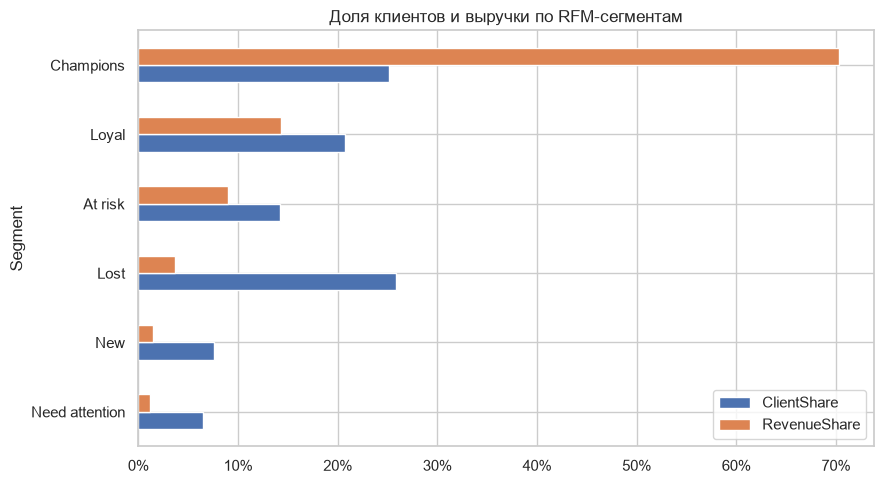

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
seg_plot = seg.sort_values("RevenueShare")[["ClientShare", "RevenueShare"]]
seg_plot.plot.barh(ax=ax)
ax.set_title("Доля клиентов и выручки по RFM-сегментам")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.savefig("../reports/figures/rfm_segments.png", dpi=150)
plt.show()